In [1]:
import os
import csv
import json
from glob import glob

import cv2
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from ultralytics.models.sam import SAM3Predictor, SAM3SemanticPredictor

PROMPT = "box"            # "text", "box", "interior", or "vertices"
TEXT_PROMPT = ["greenhouse"]
N_IMAGES = 30              # set to None to run the whole dataset
MATCH_IOU = 0.5           # IoU threshold for instance matching (mAP@.50, instance P/R/F1)
SCORE_THR = 0.25          # confidence used for instance-level P/R/F1 (mAP uses all scores)
SHOW_PLOTS = True         # set False for a fast full-dataset run
SAVE_CSV = f"metrics_{PROMPT}.csv"

overrides = {
    "conf": 0.01 if PROMPT == "text" else 0.25,   # keep low-score detections for mAP
    "task": "segment",
    "mode": "predict",
    "model": "sam3.1_multiplex.pt",  # or "sam3.pt"
    "quantize": 16,                  # FP16
    "imgsz": 1008,                   # multiple of 14 (SAM 3 native size)
    "save": False,
    "verbose": False,
}

# Text prompts -> semantic predictor (finds every instance of a concept).
# Box / point prompts -> interactive predictor (segments exactly the prompted object).
PredictorCls = SAM3SemanticPredictor if PROMPT == "text" else SAM3Predictor
predictor = PredictorCls(overrides=overrides)

In [2]:
# ---------- plotting ----------
def show_mask(mask, ax, random_color=False):
    if random_color:
        color = np.concatenate([np.random.random(3), np.array([0.6])], axis=0)
    else:
        color = np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    ax.imshow(mask.reshape(h, w, 1) * color.reshape(1, 1, -1))

def show_box(box, ax):
    x0, y0, x1, y1 = box
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0,
                               edgecolor='green', facecolor=(0, 0, 0, 0), lw=2))

# ---------- prompts / masks ----------
def interior_point(poly, H, W):
    """A point guaranteed to be inside the polygon (deepest pixel)."""
    m = np.zeros((H, W), np.uint8)
    cv2.fillPoly(m, [poly.astype(np.int32)], 1)
    dist = cv2.distanceTransform(m, cv2.DIST_L2, 5)
    y, x = np.unravel_index(dist.argmax(), dist.shape)
    return [float(x), float(y)]

def poly_to_mask(poly, H, W):
    m = np.zeros((H, W), np.uint8)
    cv2.fillPoly(m, [poly.astype(np.int32)], 1)
    return m.astype(bool)

def instances_from_results(results, H, W):
    """Return (masks: list of HxW bool, scores: list of float) for every predicted instance."""
    masks, scores = [], []
    for res in results:
        if res.masks is None:
            continue
        data = res.masks.data.cpu().numpy() > 0.5                     # (N, h, w)
        if res.boxes is not None and res.boxes.conf is not None and len(res.boxes.conf) == len(data):
            conf = res.boxes.conf.cpu().numpy().tolist()
        else:
            conf = [1.0] * len(data)                                   # prompted masks w/o score
        for inst, c in zip(data, conf):
            if inst.shape != (H, W):
                inst = cv2.resize(inst.astype(np.uint8), (W, H),
                                  interpolation=cv2.INTER_NEAREST).astype(bool)
            if inst.any():
                masks.append(inst)
                scores.append(float(c))
    return masks, scores

# ---------- metrics ----------
def safe_div(a, b):
    return a / b if b else 0.0

def pixel_counts(gt, pred):
    tp = np.logical_and(gt, pred).sum()
    fp = np.logical_and(~gt, pred).sum()
    fn = np.logical_and(gt, ~pred).sum()
    return int(tp), int(fp), int(fn)

def prf_iou(tp, fp, fn):
    p = safe_div(tp, tp + fp)
    r = safe_div(tp, tp + fn)
    f1 = safe_div(2 * p * r, p + r)
    iou = safe_div(tp, tp + fp + fn)
    return p, r, f1, iou

def mask_iou_matrix(preds, gts):
    """IoU between every predicted and every GT instance mask -> (P, G)."""
    if not preds or not gts:
        return np.zeros((len(preds), len(gts)), np.float32)
    P = np.stack(preds).reshape(len(preds), -1).astype(np.float32)
    G = np.stack(gts).reshape(len(gts), -1).astype(np.float32)
    inter = P @ G.T
    union = P.sum(1, keepdims=True) + G.sum(1) - inter
    return inter / np.maximum(union, 1)

def match_instances(pred_masks, pred_scores, gt_masks, thr=MATCH_IOU):
    """Greedy COCO-style matching by descending score. Returns per-prediction TP flags."""
    order = np.argsort(-np.asarray(pred_scores)) if pred_scores else np.array([], int)
    ious = mask_iou_matrix(pred_masks, gt_masks)
    gt_used = np.zeros(len(gt_masks), bool)
    tp_flags = np.zeros(len(pred_masks), bool)
    matched_ious = []
    for i in order:
        if len(gt_masks) == 0:
            break
        cand = np.where(~gt_used, ious[i], -1)
        j = int(cand.argmax())
        if cand[j] >= thr:
            gt_used[j] = True
            tp_flags[i] = True
            matched_ious.append(float(cand[j]))
    return tp_flags, matched_ious

def average_precision(scores, tp_flags, n_gt):
    """All-point interpolated AP (VOC2010+/COCO style) over the whole dataset."""
    if n_gt == 0:
        return float('nan')
    if len(scores) == 0:
        return 0.0
    order = np.argsort(-np.asarray(scores))
    tp = np.asarray(tp_flags, float)[order]
    fp = 1 - tp
    tp_cum, fp_cum = np.cumsum(tp), np.cumsum(fp)
    recall = tp_cum / n_gt
    precision = tp_cum / np.maximum(tp_cum + fp_cum, 1e-9)
    mrec = np.concatenate([[0.0], recall, [1.0]])
    mpre = np.concatenate([[1.0], precision, [0.0]])
    mpre = np.maximum.accumulate(mpre[::-1])[::-1]       # precision envelope
    idx = np.where(mrec[1:] != mrec[:-1])[0]
    return float(np.sum((mrec[idx + 1] - mrec[idx]) * mpre[idx + 1]))

  0%|          | 0/30 [00:00<?, ?it/s]

Ultralytics 8.4.155  Python-3.12.0 torch-2.14.0+cu130 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8123MiB)
1  pixel P 0.950 R 0.982 F1 0.966 IoU 0.934 | inst TP 5 FP 0 FN 0 F1 1.000


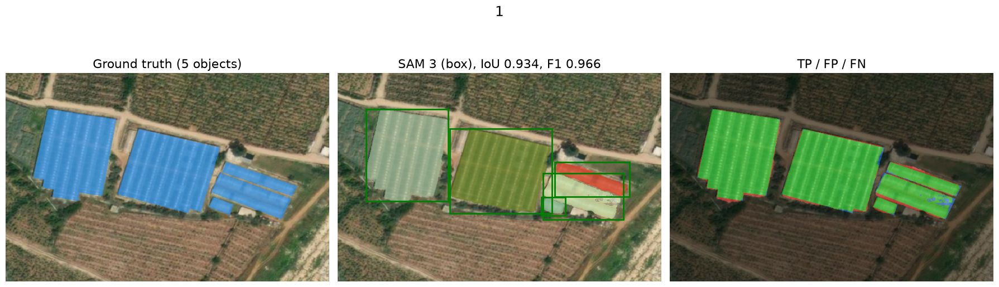

  3%|▎         | 1/30 [00:08<04:08,  8.57s/it]

10  pixel P 0.970 R 0.997 F1 0.983 IoU 0.967 | inst TP 1 FP 0 FN 0 F1 1.000


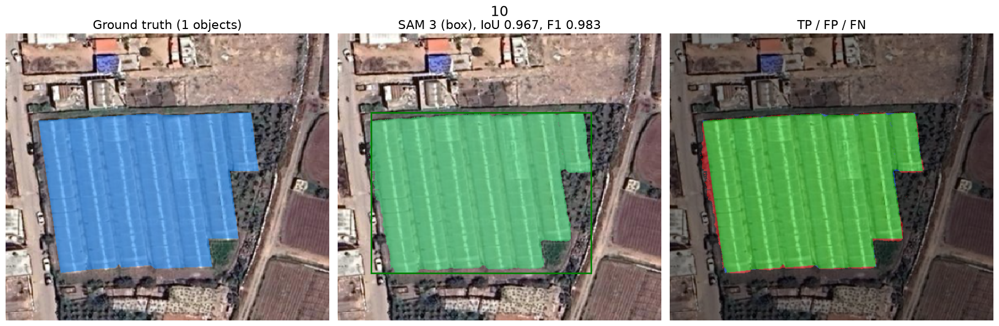

  7%|▋         | 2/30 [00:09<01:52,  4.02s/it]

100  pixel P 0.965 R 0.973 F1 0.969 IoU 0.939 | inst TP 2 FP 0 FN 0 F1 1.000


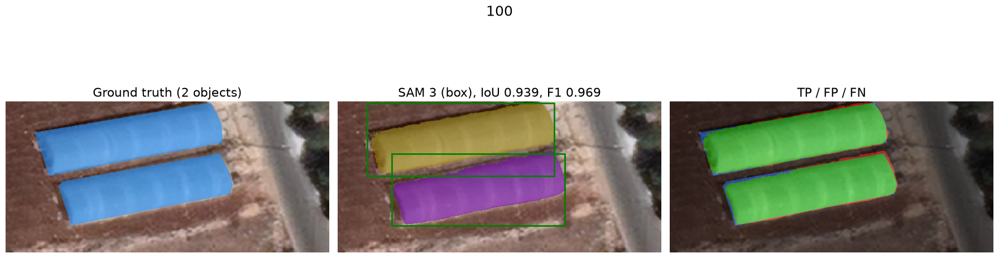

 10%|█         | 3/30 [00:10<01:06,  2.48s/it]

101  pixel P 0.975 R 0.981 F1 0.978 IoU 0.956 | inst TP 2 FP 0 FN 0 F1 1.000


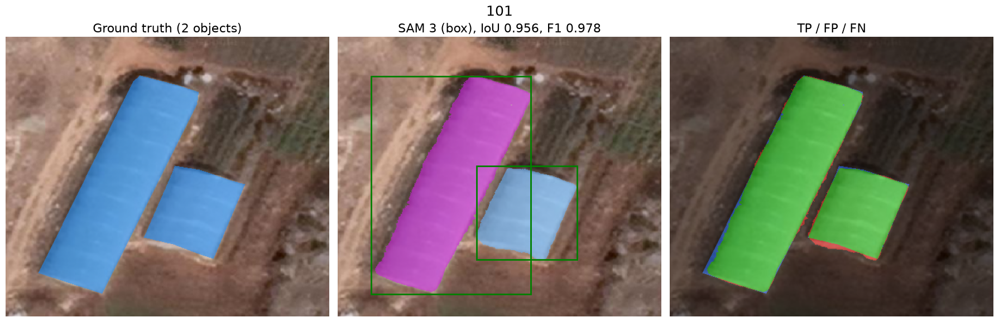

 13%|█▎        | 4/30 [00:10<00:47,  1.81s/it]

102  pixel P 0.812 R 0.989 F1 0.892 IoU 0.805 | inst TP 4 FP 0 FN 0 F1 1.000


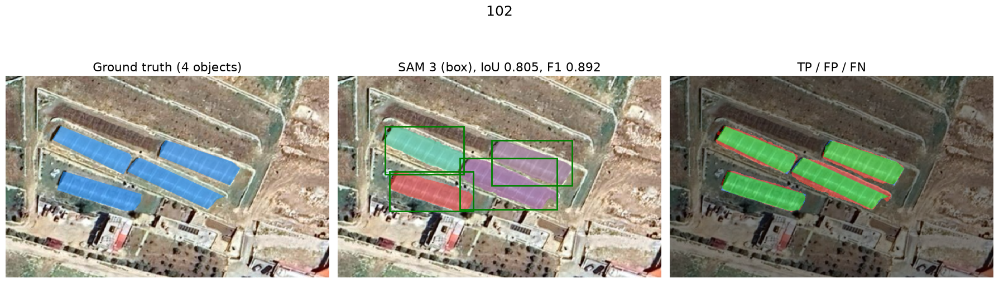

 17%|█▋        | 5/30 [00:11<00:36,  1.47s/it]

103  pixel P 0.852 R 0.972 F1 0.908 IoU 0.831 | inst TP 4 FP 0 FN 0 F1 1.000


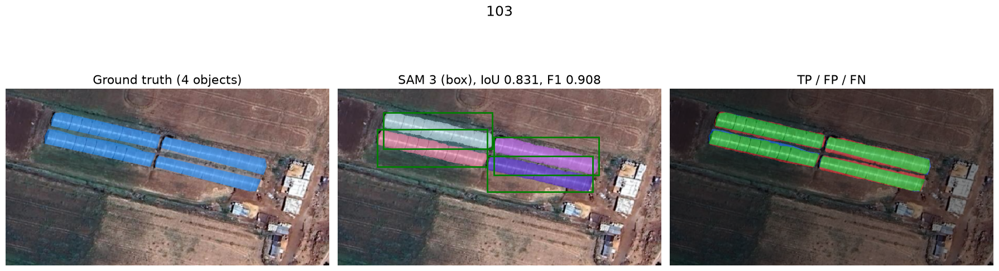

 20%|██        | 6/30 [00:12<00:31,  1.32s/it]

104  pixel P 0.891 R 0.982 F1 0.934 IoU 0.877 | inst TP 5 FP 0 FN 0 F1 1.000


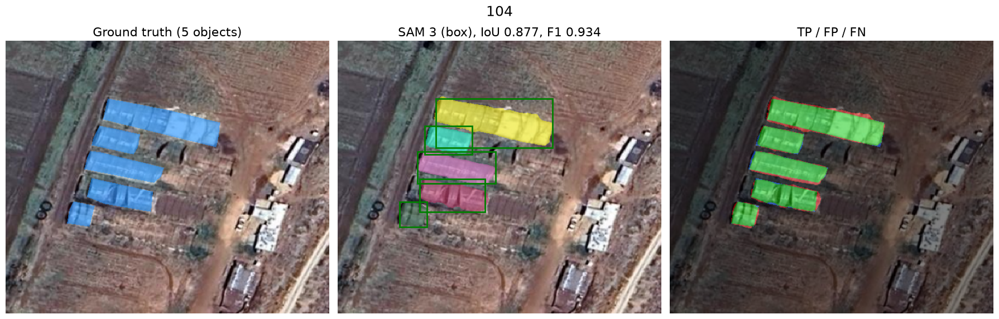

 23%|██▎       | 7/30 [00:13<00:27,  1.20s/it]

105  pixel P 0.826 R 0.990 F1 0.901 IoU 0.819 | inst TP 3 FP 0 FN 0 F1 1.000


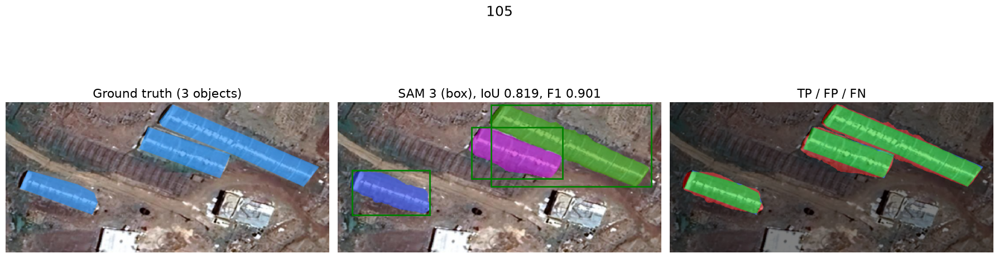

 27%|██▋       | 8/30 [00:14<00:24,  1.09s/it]

106  pixel P 0.890 R 0.966 F1 0.926 IoU 0.863 | inst TP 1 FP 0 FN 0 F1 1.000


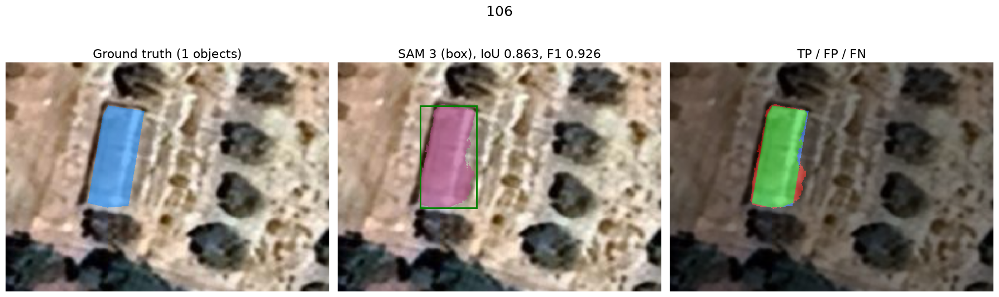

 30%|███       | 9/30 [00:15<00:20,  1.03it/s]

107  pixel P 0.934 R 0.982 F1 0.957 IoU 0.918 | inst TP 13 FP 0 FN 0 F1 1.000


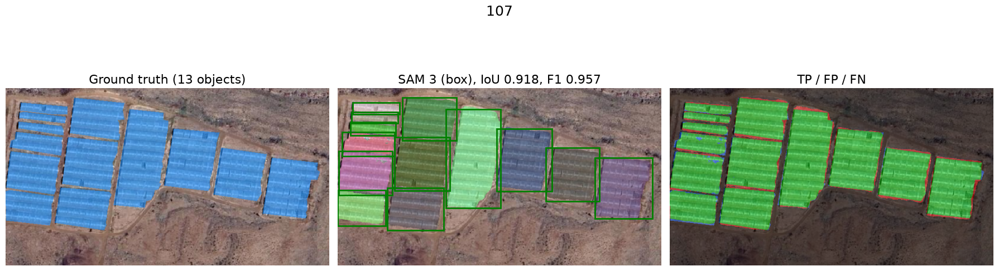

 33%|███▎      | 10/30 [00:16<00:21,  1.06s/it]

108  pixel P 0.977 R 0.991 F1 0.984 IoU 0.969 | inst TP 2 FP 0 FN 0 F1 1.000


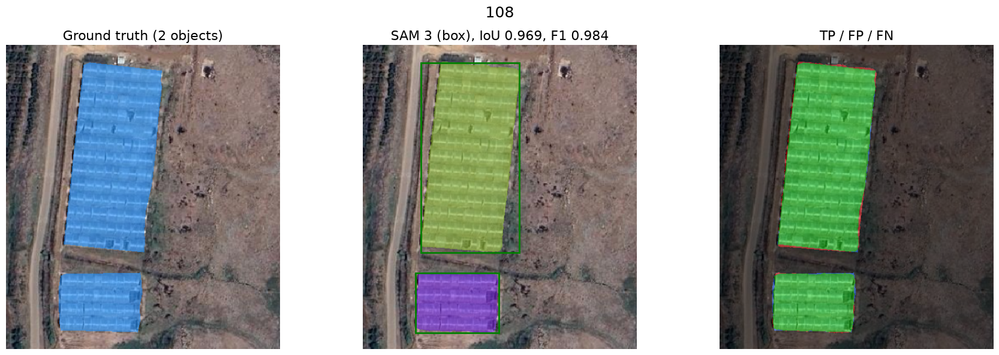

 37%|███▋      | 11/30 [00:17<00:17,  1.06it/s]

109  pixel P 0.927 R 0.978 F1 0.952 IoU 0.908 | inst TP 1 FP 0 FN 0 F1 1.000


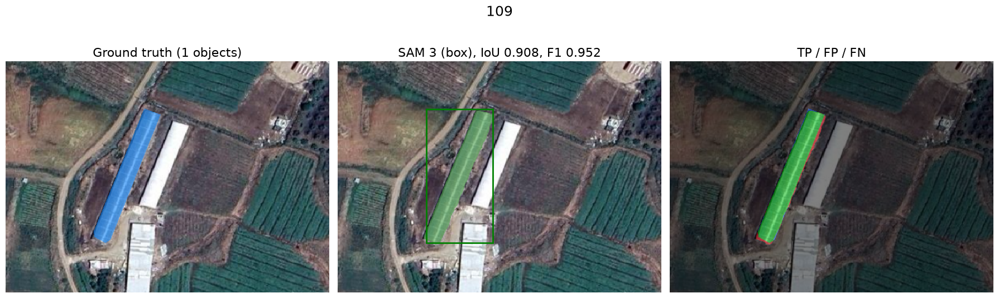

 40%|████      | 12/30 [00:17<00:15,  1.16it/s]

11  pixel P 0.956 R 0.998 F1 0.976 IoU 0.954 | inst TP 1 FP 0 FN 0 F1 1.000


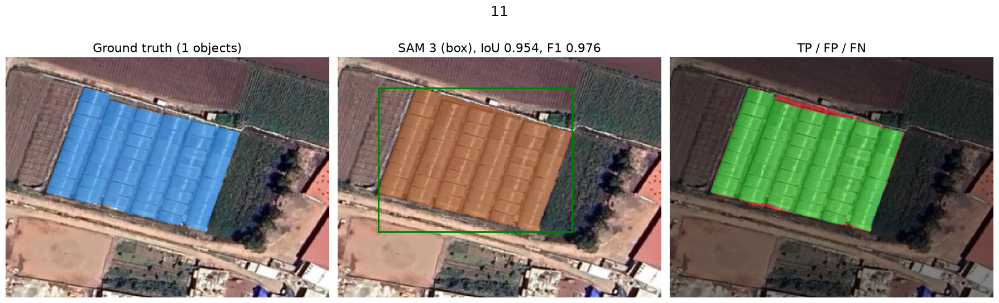

 43%|████▎     | 13/30 [00:18<00:13,  1.22it/s]

110  pixel P 0.891 R 0.992 F1 0.939 IoU 0.885 | inst TP 1 FP 0 FN 0 F1 1.000


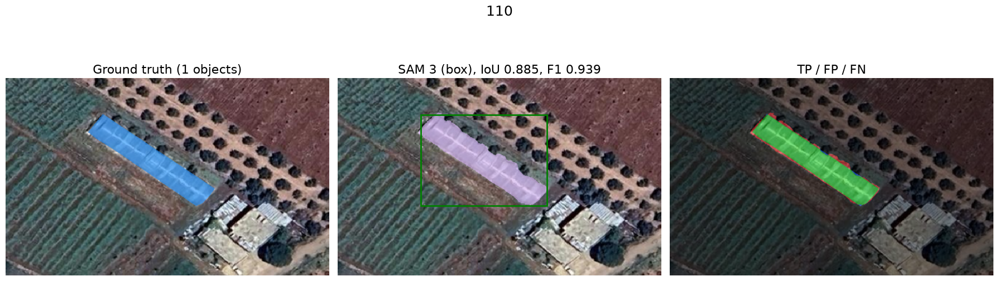

 47%|████▋     | 14/30 [00:19<00:12,  1.31it/s]

111  pixel P 0.869 R 0.728 F1 0.792 IoU 0.656 | inst TP 2 FP 0 FN 0 F1 1.000


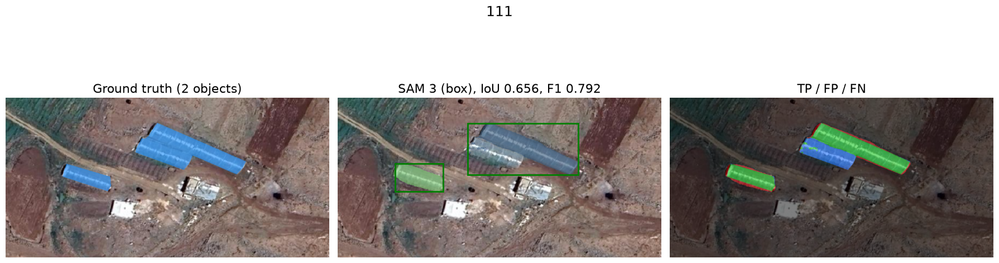

 50%|█████     | 15/30 [00:19<00:11,  1.33it/s]

112  pixel P 0.843 R 0.981 F1 0.906 IoU 0.829 | inst TP 10 FP 0 FN 0 F1 1.000


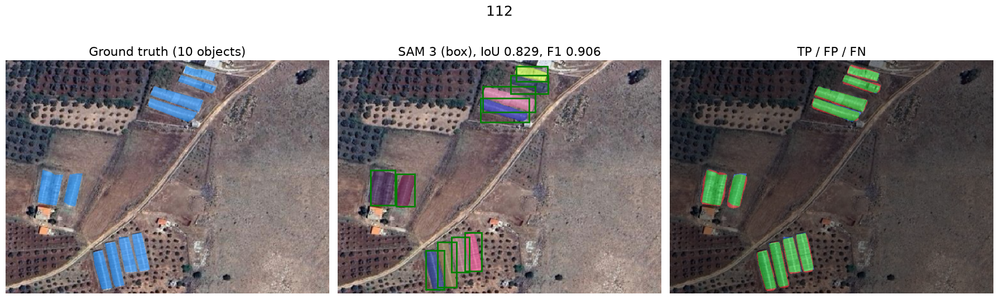

 53%|█████▎    | 16/30 [00:21<00:12,  1.11it/s]

113  pixel P 0.905 R 0.993 F1 0.947 IoU 0.900 | inst TP 7 FP 0 FN 0 F1 1.000


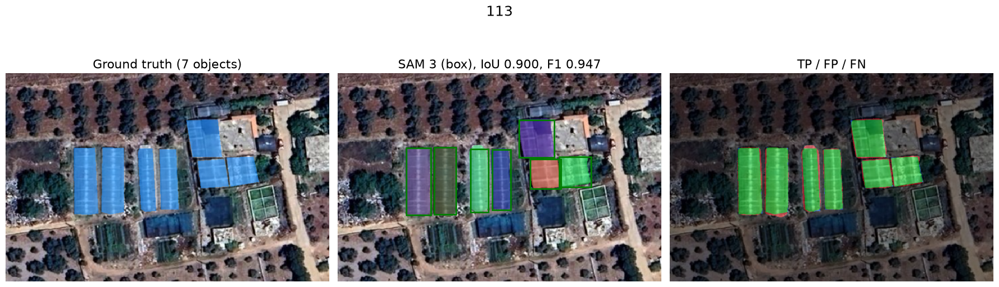

 57%|█████▋    | 17/30 [00:22<00:12,  1.08it/s]

114  pixel P 0.924 R 0.991 F1 0.956 IoU 0.916 | inst TP 5 FP 0 FN 0 F1 1.000


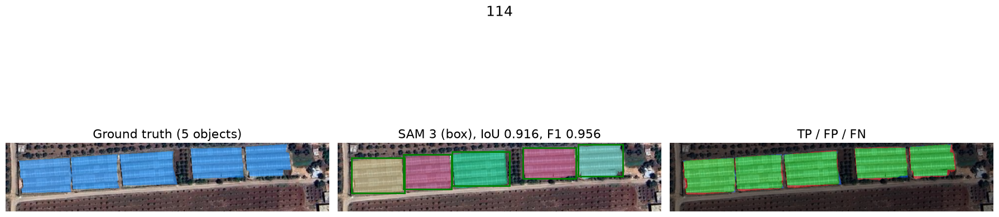

 60%|██████    | 18/30 [00:22<00:09,  1.22it/s]

115  pixel P 0.947 R 0.983 F1 0.965 IoU 0.932 | inst TP 4 FP 0 FN 0 F1 1.000


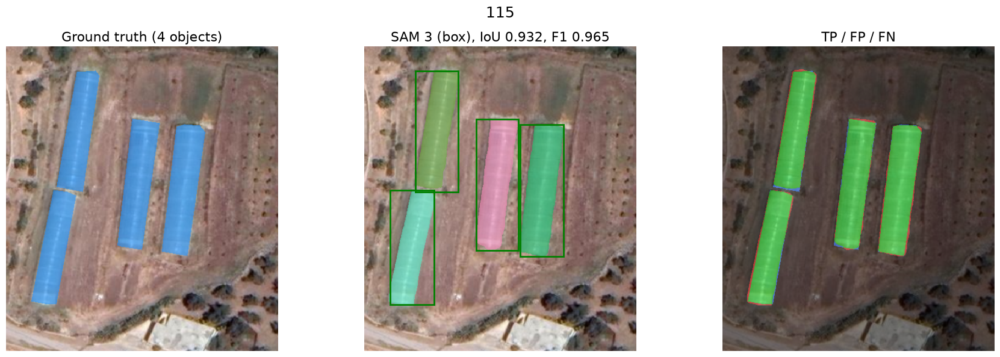

 63%|██████▎   | 19/30 [00:23<00:08,  1.22it/s]

116  pixel P 0.795 R 0.994 F1 0.884 IoU 0.792 | inst TP 2 FP 0 FN 0 F1 1.000


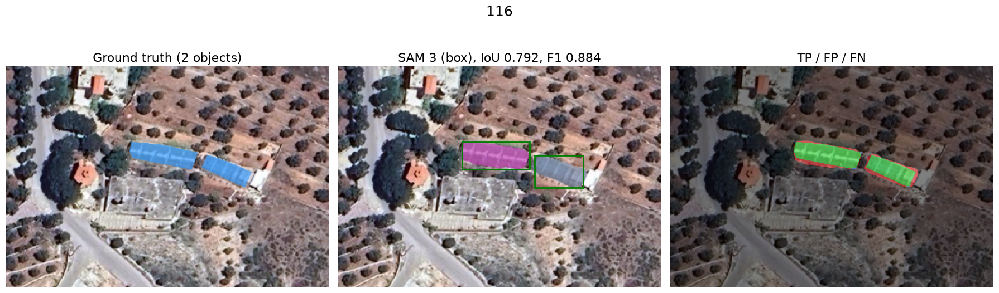

 67%|██████▋   | 20/30 [00:24<00:07,  1.26it/s]

117  pixel P 0.979 R 0.988 F1 0.983 IoU 0.967 | inst TP 1 FP 0 FN 0 F1 1.000


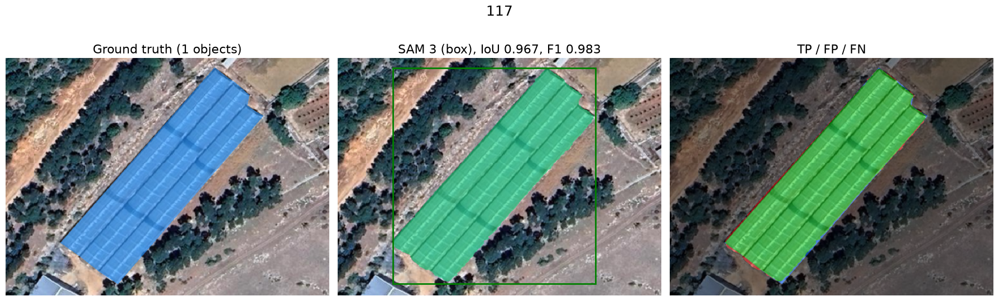

 70%|███████   | 21/30 [00:25<00:06,  1.29it/s]

118  pixel P 0.951 R 0.984 F1 0.967 IoU 0.937 | inst TP 2 FP 0 FN 0 F1 1.000


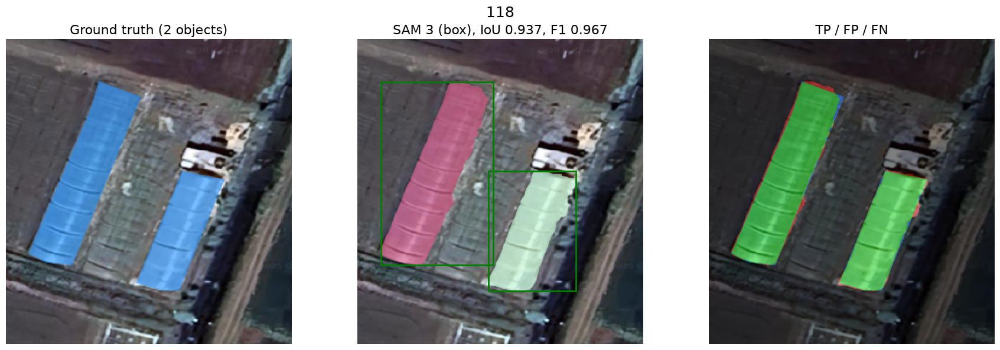

 73%|███████▎  | 22/30 [00:25<00:06,  1.32it/s]

119  pixel P 0.942 R 0.957 F1 0.949 IoU 0.903 | inst TP 5 FP 0 FN 0 F1 1.000


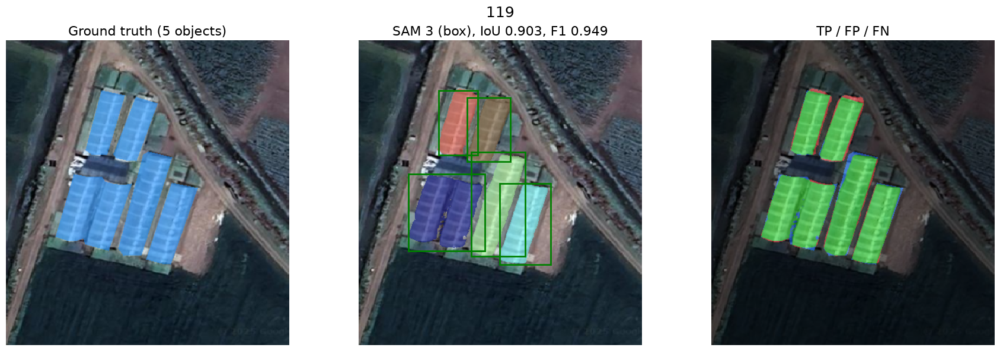

 77%|███████▋  | 23/30 [00:26<00:05,  1.28it/s]

12  pixel P 0.953 R 0.950 F1 0.952 IoU 0.908 | inst TP 2 FP 0 FN 0 F1 1.000


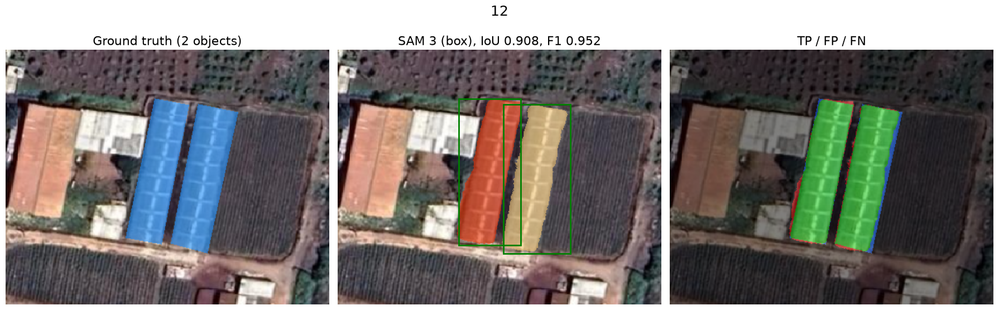

 80%|████████  | 24/30 [00:27<00:04,  1.24it/s]

120  pixel P 0.914 R 0.967 F1 0.940 IoU 0.887 | inst TP 10 FP 0 FN 0 F1 1.000


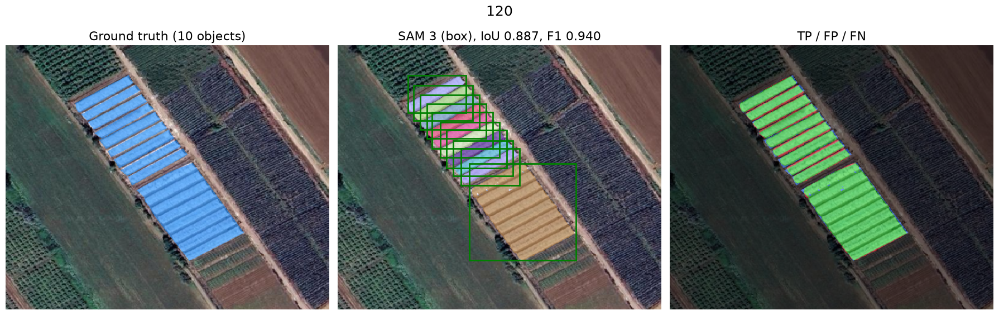

 83%|████████▎ | 25/30 [00:28<00:04,  1.08it/s]

121  pixel P 0.928 R 0.969 F1 0.948 IoU 0.901 | inst TP 1 FP 0 FN 0 F1 1.000


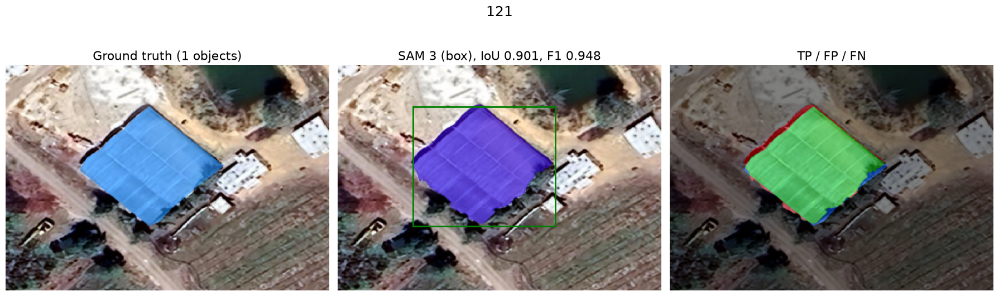

 87%|████████▋ | 26/30 [00:29<00:03,  1.16it/s]

122  pixel P 0.906 R 0.962 F1 0.933 IoU 0.875 | inst TP 14 FP 0 FN 0 F1 1.000


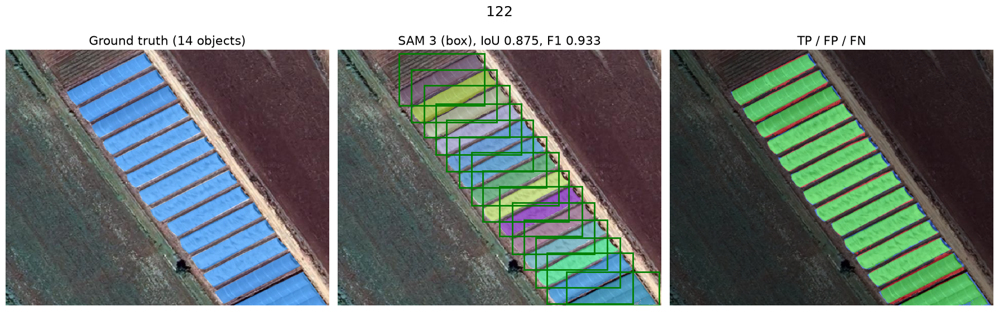

 90%|█████████ | 27/30 [00:30<00:03,  1.06s/it]

123  pixel P 0.976 R 0.966 F1 0.971 IoU 0.943 | inst TP 3 FP 0 FN 0 F1 1.000


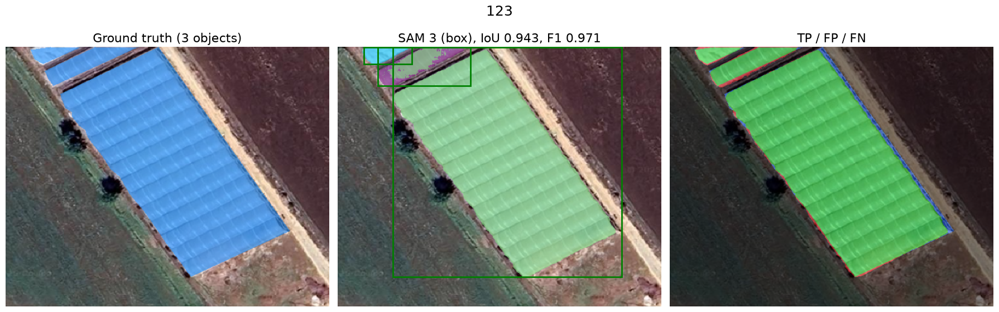

 93%|█████████▎| 28/30 [00:31<00:01,  1.01it/s]

124  pixel P 0.863 R 0.987 F1 0.921 IoU 0.854 | inst TP 1 FP 0 FN 0 F1 1.000


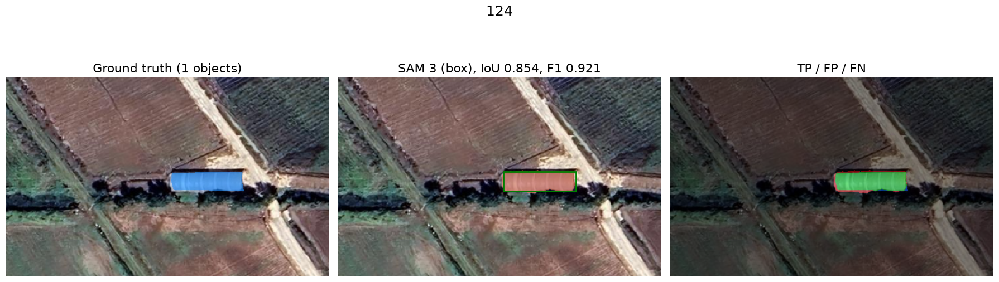

 97%|█████████▋| 29/30 [00:32<00:00,  1.12it/s]

125  pixel P 0.935 R 0.974 F1 0.954 IoU 0.912 | inst TP 1 FP 0 FN 0 F1 1.000


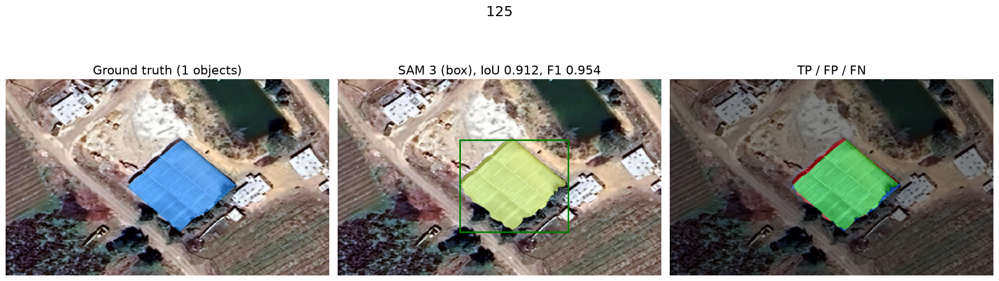

100%|██████████| 30/30 [00:33<00:00,  1.10s/it]


In [3]:
images = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\images'
masks  = r'C:\Users\alias\Documents\UNI\Thesis\GreenHouse-Dataset_Images+jsonlabels+masks\Greenhousedataset\masks'

img_paths = sorted(glob(os.path.join(images, '*.png')))[:N_IMAGES]

rows = []                                   # per-image metrics
pix_tot = np.zeros(3, np.int64)             # dataset-wide pixel TP, FP, FN
all_scores, all_tp = [], []                 # dataset-wide instance detections (for mAP)
n_gt_total = 0
inst_tp = inst_fp = inst_fn = 0             # instance counts at SCORE_THR

for img_path in tqdm(img_paths):
    stem = os.path.splitext(os.path.basename(img_path))[0]
    mask_path = os.path.join(masks, stem + '.png')      # pair by name, not by glob order
    json_path = os.path.join(images, stem + '.json')
    if not (os.path.exists(mask_path) and os.path.exists(json_path)):
        print(f"skipping {stem}: missing mask or json")
        continue

    image_bgr = cv2.imread(img_path)                     # Ultralytics expects BGR arrays
    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)   # RGB only for plotting
    gt = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE) > 0
    H, W = image.shape[:2]

    with open(json_path) as fh:
        ann = json.load(fh)
    polygons = [np.array(s['points'], dtype=np.float32).reshape(-1, 2)
                for s in ann['shapes'] if len(s['points']) >= 3]
    gt_insts = [poly_to_mask(p, H, W) for p in polygons]
    gt_insts = [m for m in gt_insts if m.any()]

    predictor.set_image(image_bgr)
    boxes = [[*map(float, p.min(0)), *map(float, p.max(0))] for p in polygons]

    # ---- predict instances ----
    if PROMPT == "text":
        pm, ps = instances_from_results(predictor(text=TEXT_PROMPT), H, W)
    elif not polygons:
        pm, ps = [], []
    elif PROMPT == "box":
        pm, ps = instances_from_results(predictor(bboxes=boxes), H, W)
    elif PROMPT == "interior":
        pts = [interior_point(p, H, W) for p in polygons]
        pm, ps = instances_from_results(predictor(points=pts, labels=[1] * len(pts)), H, W)
    elif PROMPT == "vertices":
        pm, ps = [], []
        for p in polygons:                                  # many points, one object
            m_, s_ = instances_from_results(predictor(points=[p.tolist()], labels=[[1] * len(p)]), H, W)
            if m_:                                          # keep one mask per prompted object
                k = int(np.argmax(s_))
                pm.append(m_[k]); ps.append(s_[k])
    else:
        raise ValueError(f"unknown PROMPT {PROMPT!r}")

    # ---- instance-level: matching for mAP and P/R/F1 at SCORE_THR ----
    tp_flags, _ = match_instances(pm, ps, gt_insts)
    all_scores += ps
    all_tp += tp_flags.tolist()
    n_gt_total += len(gt_insts)

    keep = [i for i, s in enumerate(ps) if s >= SCORE_THR]
    pm_k, ps_k = [pm[i] for i in keep], [ps[i] for i in keep]
    tp_k, matched_ious = match_instances(pm_k, ps_k, gt_insts)
    i_tp, i_fp = int(tp_k.sum()), int((~tp_k).sum())
    i_fn = len(gt_insts) - i_tp
    inst_tp += i_tp; inst_fp += i_fp; inst_fn += i_fn

    # ---- pixel-level (semantic) metrics on the merged mask ----
    pred = np.zeros((H, W), bool)
    for m in pm_k:
        pred |= m
    tp, fp, fn = pixel_counts(gt, pred)
    pix_tot += (tp, fp, fn)
    p, r, f1, iou_v = prf_iou(tp, fp, fn)
    ip, ir, if1, _ = prf_iou(i_tp, i_fp, i_fn)

    rows.append(dict(image=stem, n_gt=len(gt_insts), n_pred=len(pm_k),
                     pix_precision=p, pix_recall=r, pix_f1=f1, pix_iou=iou_v,
                     inst_tp=i_tp, inst_fp=i_fp, inst_fn=i_fn,
                     inst_precision=ip, inst_recall=ir, inst_f1=if1,
                     mean_matched_iou=float(np.mean(matched_ious)) if matched_ious else 0.0))
    print(f"{stem}  pixel P {p:.3f} R {r:.3f} F1 {f1:.3f} IoU {iou_v:.3f} | "
          f"inst TP {i_tp} FP {i_fp} FN {i_fn} F1 {if1:.3f}")

    if SHOW_PLOTS:
        err = np.zeros((H, W, 3), np.uint8)              # green = TP, red = FP, blue = FN
        err[gt & pred] = (0, 200, 0)
        err[~gt & pred] = (220, 0, 0)
        err[gt & ~pred] = (0, 90, 255)

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        axes[0].imshow(image); show_mask(gt, axes[0])
        axes[0].set_title(f"Ground truth ({len(gt_insts)} objects)", fontsize=16)
        axes[1].imshow(image)
        for m in pm_k:
            show_mask(m, axes[1], random_color=True)
        if PROMPT == "box":
            for b in boxes:
                show_box(b, axes[1])
        axes[1].set_title(f"SAM 3 ({PROMPT}), IoU {iou_v:.3f}, F1 {f1:.3f}", fontsize=16)
        axes[2].imshow(image); axes[2].imshow(err, alpha=0.5)
        axes[2].set_title("TP / FP / FN", fontsize=16)
        for ax in axes:
            ax.axis('off')
        fig.suptitle(stem, fontsize=18)
        plt.tight_layout()
        plt.show()

In [4]:
# ---------- dataset summary ----------
P, R, F1, IOU = prf_iou(*pix_tot)                                   # micro (all pixels pooled)
mean = lambda k: float(np.mean([r[k] for r in rows])) if rows else 0.0
iP, iR, iF1, _ = prf_iou(inst_tp, inst_fp, inst_fn)
mAP50 = average_precision(all_scores, all_tp, n_gt_total)

print(f"\n===== {PROMPT} prompt, {len(rows)} images, {n_gt_total} GT objects =====")
print("Pixel-level (micro, all pixels pooled)")
print(f"  Precision {P:.4f}  Recall {R:.4f}  F1 {F1:.4f}  IoU {IOU:.4f}")
print("Pixel-level (macro, mean over images)")
print(f"  Precision {mean('pix_precision'):.4f}  Recall {mean('pix_recall'):.4f}  "
      f"F1 {mean('pix_f1'):.4f}  mIoU {mean('pix_iou'):.4f}")
print(f"Instance-level (mask IoU >= {MATCH_IOU}, score >= {SCORE_THR})")
print(f"  TP {inst_tp}  FP {inst_fp}  FN {inst_fn}  Precision {iP:.4f}  Recall {iR:.4f}  F1 {iF1:.4f}")
print(f"  mAP@.50 (mask) {mAP50:.4f}")

if SAVE_CSV and rows:
    with open(SAVE_CSV, "w", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(rows[0].keys()))
        w.writeheader()
        w.writerows(rows)
    print(f"\nPer-image metrics saved to {os.path.abspath(SAVE_CSV)}")


===== box prompt, 30 images, 115 GT objects =====
Pixel-level (micro, all pixels pooled)
  Precision 0.9252  Recall 0.9769  F1 0.9504  IoU 0.9054
Pixel-level (macro, mean over images)
  Precision 0.9148  Recall 0.9716  F1 0.9411  mIoU 0.8912
Instance-level (mask IoU >= 0.5, score >= 0.25)
  TP 115  FP 0  FN 0  Precision 1.0000  Recall 1.0000  F1 1.0000
  mAP@.50 (mask) 1.0000

Per-image metrics saved to c:\Users\alias\Documents\UNI\Thesis\Codes\test-sam\metrics_box.csv
